# Student Performance Analysis and Prediction Using Machine Learning


## 1. Importing Required Libraries


In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading the Dataset

In [3]:
df = pd.read_csv('/content/student-mat.csv', sep=';')

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 3. Understanding the Dataset

In [5]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [6]:
df.tail()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9


In [7]:
print("Shape of dataset:", df.shape)

Shape of dataset: (395, 33)


In [8]:
print(df.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [10]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [11]:
print(df.isnull().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


## 4. Data Cleaning

In [12]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [13]:
df = df.drop_duplicates()

print("Duplicates removed successfully!")

Duplicates removed successfully!


In [14]:
print(df.dtypes)

school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


## 5. Exploratory Data Analysis (EDA)

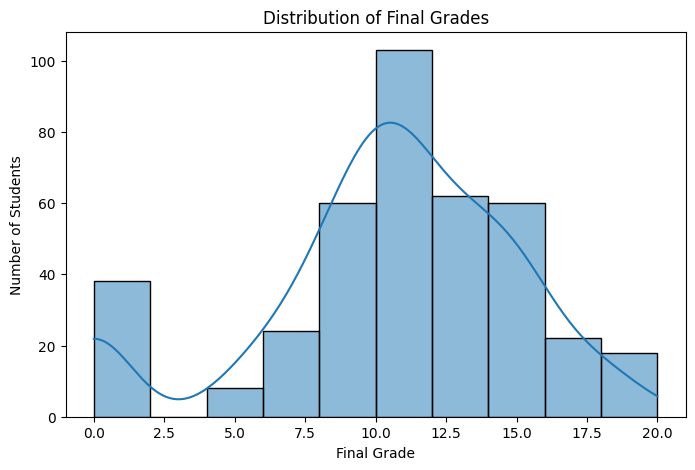

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df['G3'], bins=10, kde=True)

plt.title('Distribution of Final Grades')
plt.xlabel('Final Grade')
plt.ylabel('Number of Students')

plt.show()

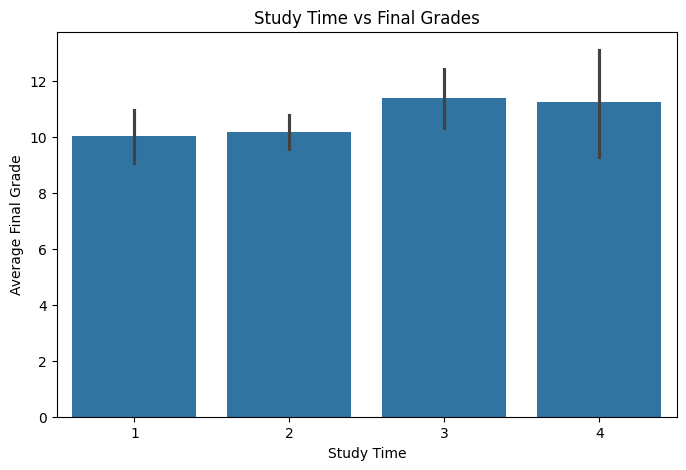

In [16]:
plt.figure(figsize=(8,5))

sns.barplot(x='studytime', y='G3', data=df)

plt.title('Study Time vs Final Grades')
plt.xlabel('Study Time')
plt.ylabel('Average Final Grade')

plt.show()

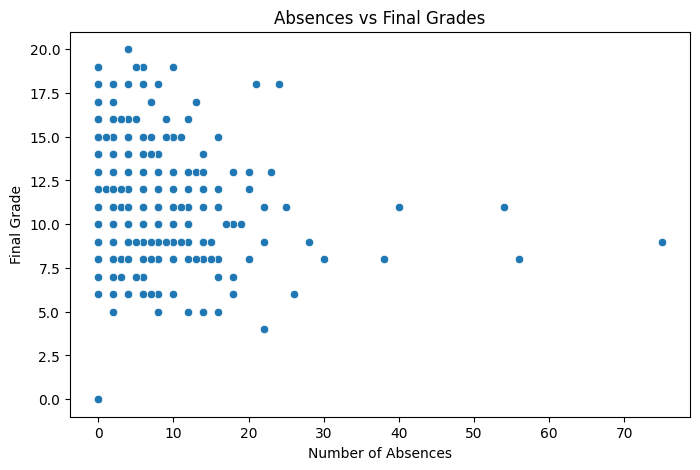

In [17]:
plt.figure(figsize=(8,5))

sns.scatterplot(x='absences', y='G3', data=df)

plt.title('Absences vs Final Grades')
plt.xlabel('Number of Absences')
plt.ylabel('Final Grade')

plt.show()

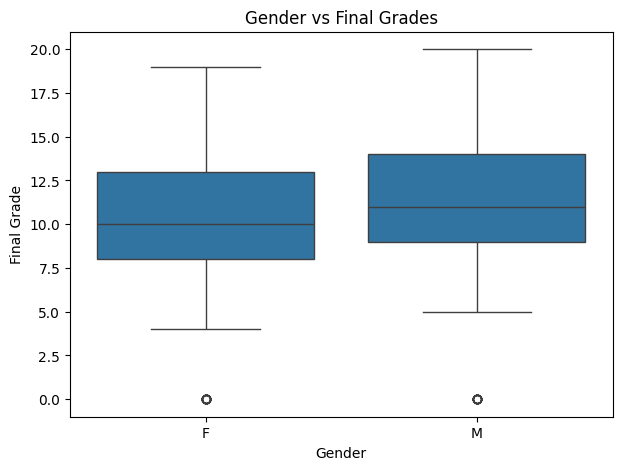

In [18]:
plt.figure(figsize=(7,5))

sns.boxplot(x='sex', y='G3', data=df)

plt.title('Gender vs Final Grades')
plt.xlabel('Gender')
plt.ylabel('Final Grade')

plt.show()

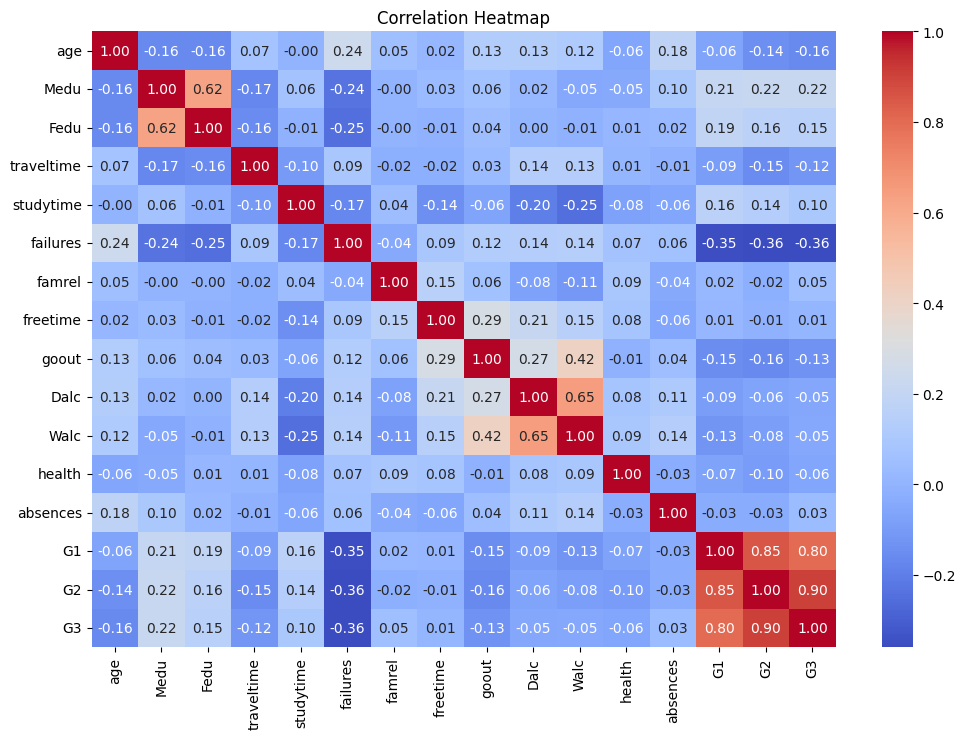

In [19]:
plt.figure(figsize=(12,8))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

## 6. Data Preprocessing

In [20]:
X = df.drop(columns=['G1', 'G2', 'G3'])

y = df['G3']

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (395, 30)
Target: (395,)


In [21]:
X = pd.get_dummies(X, drop_first=True)

print(X.head())

   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   18     4     4           2          2         0       4         3      4   
1   17     1     1           1          2         0       5         3      3   
2   15     1     1           1          2         3       4         3      2   
3   15     4     2           1          3         0       3         2      2   
4   16     3     3           1          2         0       4         3      2   

   Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
0     1  ...             True           False           True       False   
1     1  ...            False           False          False        True   
2     2  ...             True           False           True       False   
3     1  ...             True           False          False        True   
4     1  ...            False           False          False        True   

   paid_yes  activities_yes  nursery_yes  higher_yes  internet

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 316
Testing records: 79


## 7. Linear Regression

In [23]:
model = LinearRegression()

In [24]:
model.fit(X_train, y_train)

LinearRegression()

In [25]:
y_pred = model.predict(X_test)

In [26]:
results = pd.DataFrame({
    'Actual Marks': y_test.values,
    'Predicted Marks': y_pred.round(2)
})

print(results.head(10))

   Actual Marks  Predicted Marks
0            10             1.89
1            12             7.45
2             5             8.31
3            10            11.55
4             9            10.20
5            13             9.43
6            18            13.21
7             6            12.69
8             0            10.27
9            14            12.34


In [27]:
print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 3.39526092580192
MSE: 17.603737398324714
R2 Score: 0.14149247411195787


### Preparing Data for Pass/Fail Classification

In [28]:
y_class = (df['G3'] >= 10).astype(int)

print(y_class.value_counts())

G3
1    265
0    130
Name: count, dtype: int64


In [29]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

In [30]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_c)

X_test_scaled = scaler.transform(X_test_c)

## 8. Logistic Regression

In [31]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train_c)

LogisticRegression(max_iter=1000)

In [32]:
log_predictions = log_model.predict(X_test_scaled)

In [33]:
print(
    "Logistic Regression Accuracy:",
    accuracy_score(y_test_c, log_predictions)
)

print(classification_report(y_test_c, log_predictions))

Logistic Regression Accuracy: 0.6329113924050633
              precision    recall  f1-score   support

           0       0.43      0.35      0.38        26
           1       0.71      0.77      0.74        53

    accuracy                           0.63        79
   macro avg       0.57      0.56      0.56        79
weighted avg       0.62      0.63      0.62        79



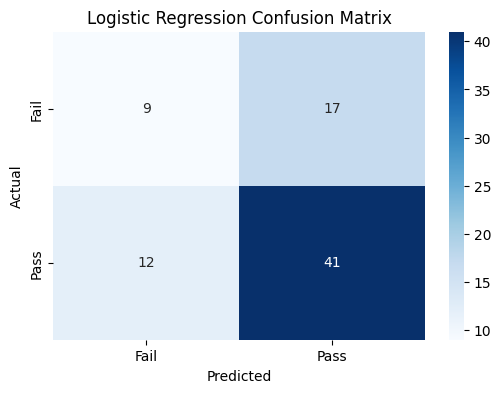

In [42]:
cm = confusion_matrix(y_test_c, log_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

## 9. Decision Tree Classification

In [34]:
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

In [35]:
tree_model.fit(X_train_c, y_train_c)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [36]:
tree_predictions = tree_model.predict(X_test_c)

In [37]:
print(
    "Decision Tree Accuracy:",
    accuracy_score(y_test_c, tree_predictions)
)

Decision Tree Accuracy: 0.6708860759493671


In [43]:
print(classification_report(y_test_c, tree_predictions))

              precision    recall  f1-score   support

           0       0.50      0.35      0.41        26
           1       0.72      0.83      0.77        53

    accuracy                           0.67        79
   macro avg       0.61      0.59      0.59        79
weighted avg       0.65      0.67      0.65        79



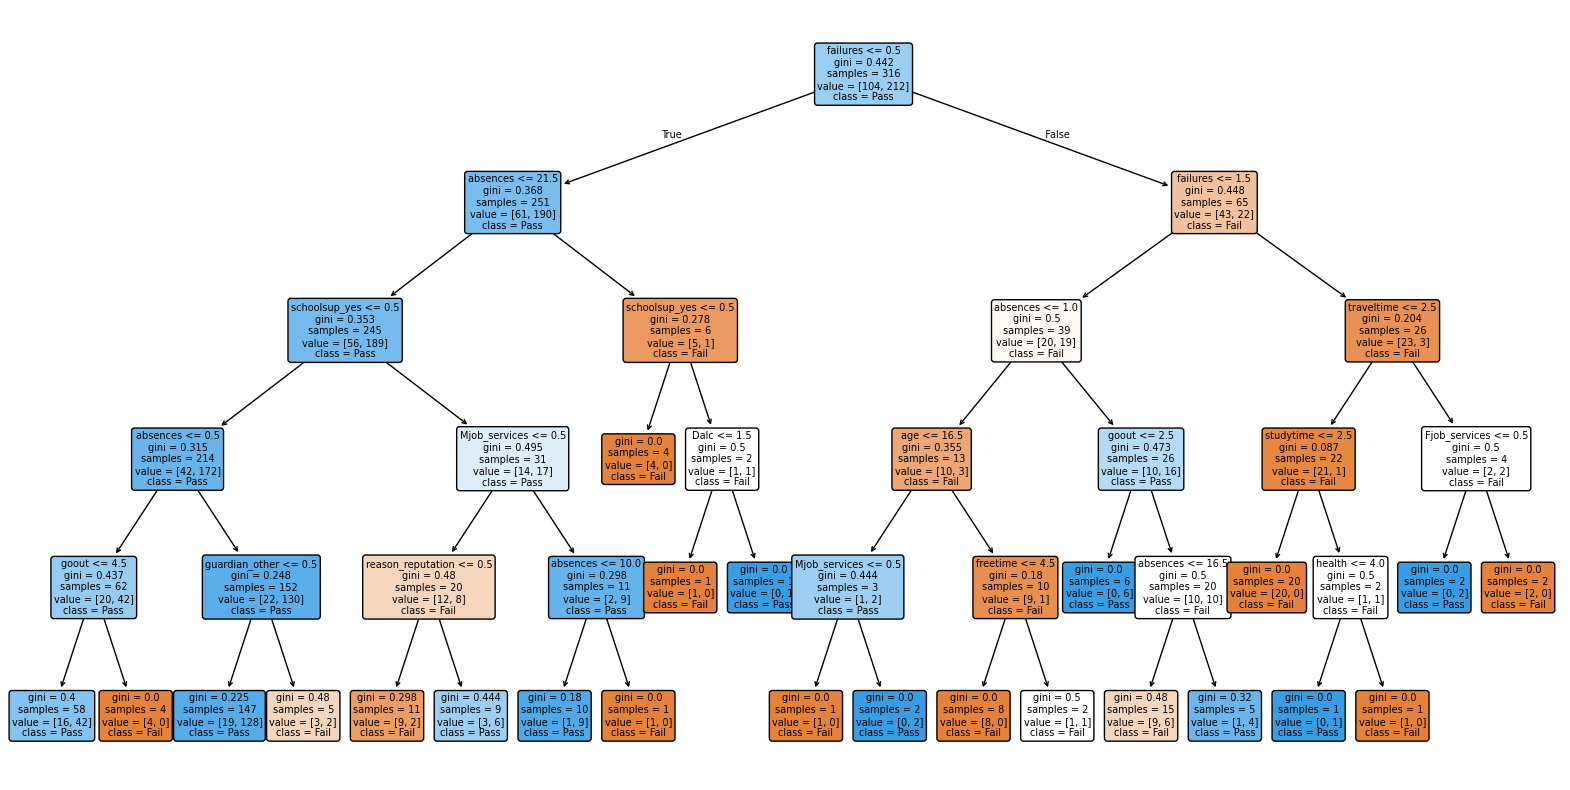

In [38]:
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=['Fail', 'Pass'],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.show()

## 10. Model Comparison

In [39]:
comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test_c, log_predictions),
        accuracy_score(y_test_c, tree_predictions)
    ]
})

print(comparison)

                 Model  Accuracy
0  Logistic Regression  0.632911
1        Decision Tree  0.670886


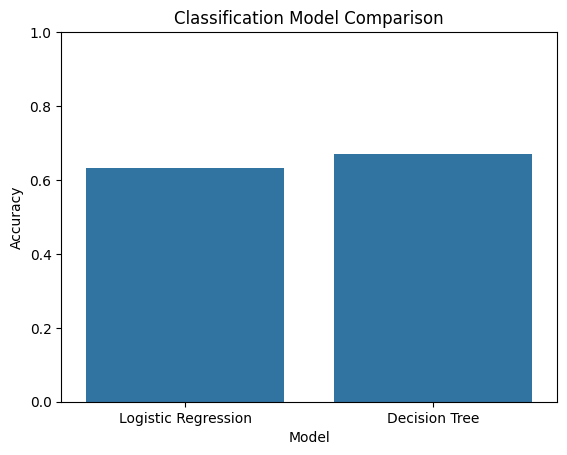

In [40]:
sns.barplot(
    x='Model',
    y='Accuracy',
    data=comparison
)

plt.title('Classification Model Comparison')
plt.ylim(0, 1)
plt.show()

## 11. Conclusion

This project analysed student performance using Python and machine learning techniques. The dataset was explored and cleaned, and different visualisations were created to understand factors related to students' final grades.

Linear Regression was used to predict final marks, while Logistic Regression and Decision Tree Classification were used to predict pass/fail results.

Among the two classification models, Decision Tree achieved a higher accuracy of 67.09%, compared with 63.29% for Logistic Regression.

The project demonstrates how data analysis and machine learning can help study student performance.